<a href="https://colab.research.google.com/github/jesuscarpio5/Analisis-deportivo/blob/main/final_mundial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install mplsoccer statsbombpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [mplsoccer]


In [2]:
from statsbombpy import sb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mplsoccer import Pitch
import warnings
warnings.filterwarnings("ignore")

MATCH_ID = 8658   # Final Mundial 2018: Francia - Croacia

partidos = sb.matches(competition_id=43, season_id=3)
info = partidos[partidos.match_id == MATCH_ID].iloc[0]
titulo_partido = (f"{info.home_team} {info.home_score}-{info.away_score} {info.away_team} "
                  f"| {info.competition_stage} | {info.match_date}")

eventos_partido = sb.events(match_id=MATCH_ID)
eventos_partido = eventos_partido[eventos_partido.period < 5]  # sin tanda de penaltis
print(titulo_partido)
print(eventos_partido.team.unique())

France 4-2 Croatia | Final | 2018-07-15
['France' 'Croatia']


In [3]:
def informe(equipo, eventos_partido=eventos_partido, titulo=titulo_partido, guardar=True):
    ev = eventos_partido[eventos_partido.team == equipo]

    # --- Pases progresivos ---
    pases = ev[(ev.type == "Pass") & (ev.pass_outcome.isna())].dropna(subset=["pass_end_location"]).copy()
    pases[["x", "y"]] = pd.DataFrame(pases.location.tolist(), index=pases.index)
    pases[["x2", "y2"]] = pd.DataFrame(pases.pass_end_location.tolist(), index=pases.index)
    d_ini = np.sqrt((120 - pases.x) ** 2 + (40 - pases.y) ** 2)
    d_fin = np.sqrt((120 - pases.x2) ** 2 + (40 - pases.y2) ** 2)
    prog = pases[(d_fin < 0.75 * d_ini) & (pases.x2 > pases.x)]

    # --- Tiros ---
    tiros = ev[ev.type == "Shot"].copy()
    tiros[["x", "y"]] = pd.DataFrame(tiros.location.tolist(), index=tiros.index)
    goles = tiros[tiros.shot_outcome == "Goal"]
    otros = tiros[tiros.shot_outcome != "Goal"]
    xg_total = tiros.shot_statsbomb_xg.sum()

    # --- Recuperaciones ---
    recup = ev[ev.type.isin(["Ball Recovery", "Interception"])].copy()
    recup[["x", "y"]] = pd.DataFrame(recup.location.tolist(), index=recup.index)

    # --- Página ---
    fig = plt.figure(figsize=(11.69, 8.27))  # A4 horizontal
    fig.suptitle(f"Informe de partido: {equipo}", fontsize=20, fontweight="bold", y=0.97)
    fig.text(0.5, 0.925, titulo, ha="center", fontsize=11, color="#444444")
    resumen = (f"Pases completados: {len(pases)}   |   Progresivos: {len(prog)} "
               f"({len(prog) / max(len(pases), 1) * 100:.0f}%)   |   Tiros: {len(tiros)}   |   "
               f"xG: {xg_total:.2f}   |   Goles: {len(goles)}   |   Recuperaciones: {len(recup)}")
    fig.text(0.5, 0.895, resumen, ha="center", fontsize=10, color="#444444")

    ax1 = fig.add_axes([0.02, 0.08, 0.31, 0.76])
    ax2 = fig.add_axes([0.35, 0.08, 0.31, 0.76])
    ax3 = fig.add_axes([0.68, 0.08, 0.31, 0.76])

    # 1) Pases progresivos: flechas
    p1 = Pitch(pitch_type="statsbomb", line_color="#999999")
    p1.draw(ax=ax1)
    p1.arrows(prog.x, prog.y, prog.x2, prog.y2, ax=ax1,
              width=2, headwidth=4, color="#1f77b4", alpha=0.6)
    ax1.set_title(f"Pases progresivos ({len(prog)})", fontsize=11)

    # 2) Tiros con xG
    p2 = Pitch(pitch_type="statsbomb", line_color="#999999", half=True)
    p2.draw(ax=ax2)
    p2.scatter(otros.x, otros.y, s=otros.shot_statsbomb_xg * 500 + 20, ax=ax2,
               color="#1f77b4", alpha=0.5, edgecolors="white")
    p2.scatter(goles.x, goles.y, s=goles.shot_statsbomb_xg * 500 + 20, ax=ax2,
               color="#d62728", alpha=0.9, edgecolors="white")
    ax2.set_title("Tiros (tamaño = xG, rojo = gol)", fontsize=11)

    # 3) Recuperaciones
    p3 = Pitch(pitch_type="statsbomb", line_color="#999999")
    p3.draw(ax=ax3)
    if len(recup) > 0:
        b3 = p3.bin_statistic(recup.x, recup.y, statistic="count", bins=(6, 5), normalize=True)
        p3.heatmap(b3, ax=ax3, cmap="Greens", edgecolor="white")
        p3.label_heatmap(b3, ax=ax3, str_format="{:.0%}", color="black",
                         fontsize=9, ha="center", va="center")
    ax3.set_title("Zonas de recuperación", fontsize=11)

    fig.text(0.5, 0.02, "Datos: StatsBomb Open Data | El equipo ataca de izquierda a derecha",
             ha="center", fontsize=8, color="#777777")

    if guardar:
        nombre = f"informe_{equipo.replace(' ', '_')}_{MATCH_ID}"
        fig.savefig(f"{nombre}.pdf")
        fig.savefig(f"{nombre}.png", dpi=200)
    plt.show()

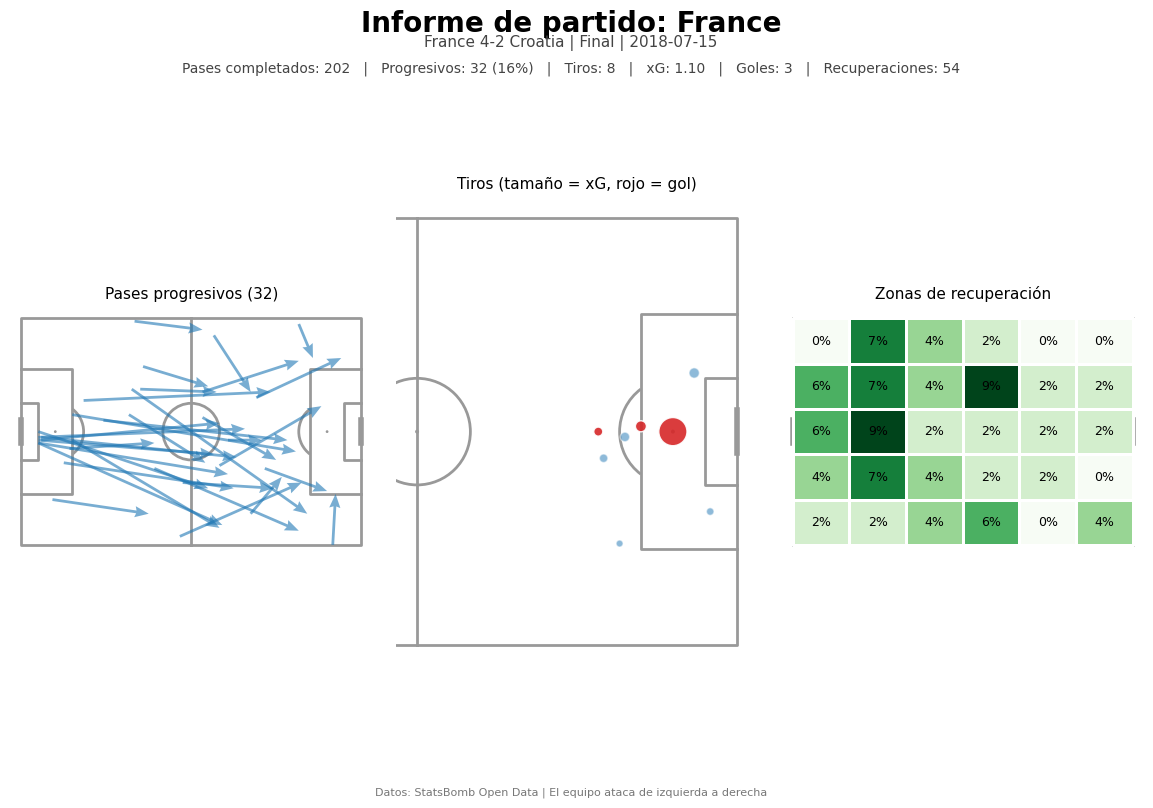

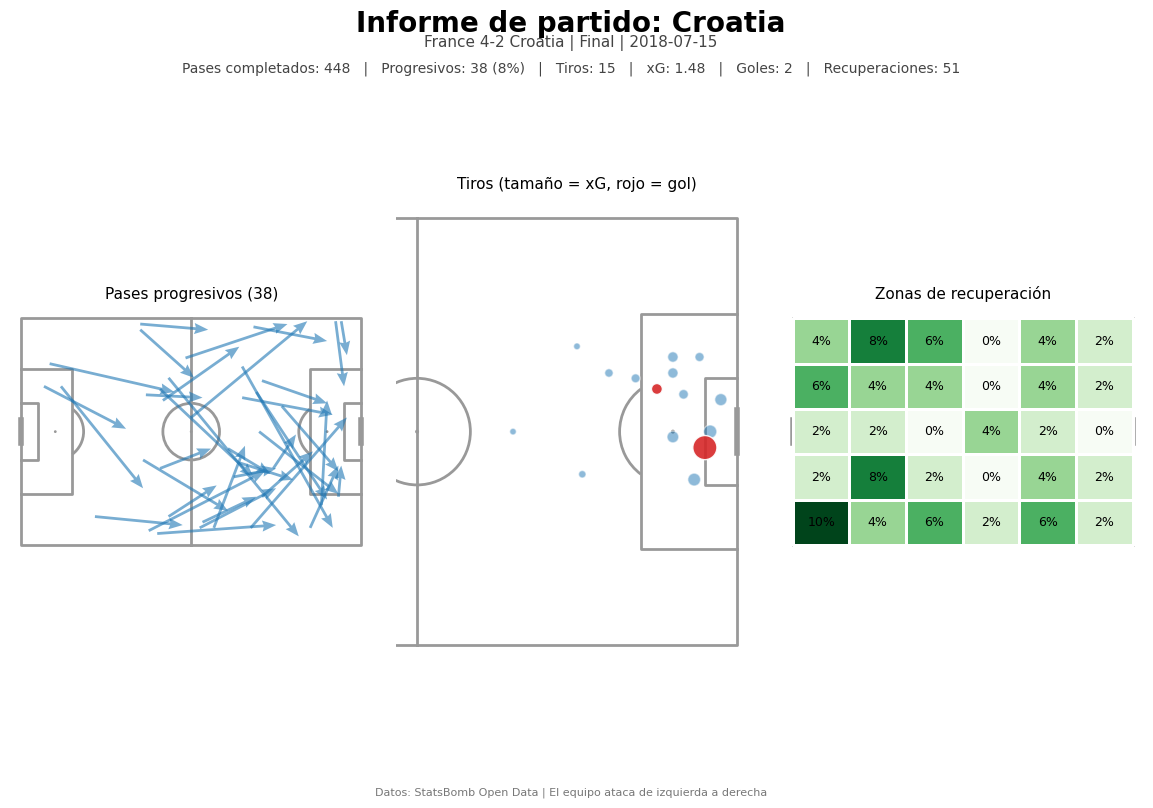

In [4]:
informe("France")
informe("Croatia")